<a href="https://colab.research.google.com/github/nehafatima318/hr_analytics/blob/main/hranalytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

In [3]:
df= pd.read_csv('/content/sample_data/HR_comma_sep.csv')
df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [4]:
import seaborn as sns
# 1. Print dataset columns to identify the retention target variable
print("Columns in dataset:", df.columns.tolist())

# Display basic summary statistics
display(df.describe())

Columns in dataset: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'left', 'promotion_last_5years', 'Department', 'salary']


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [5]:
# 2. Analyze the averages of numeric features grouped by 'left'
# This will instantly show us which features have significant differences between those who left and those who stayed.
retention_summary = df.groupby('left').mean(numeric_only=True)
display(retention_summary)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years
left,,,,,,,
0,0.666810,0.715473,3.786664,199.060203,3.380032,0.175009,0.026251
1,0.440098,0.718113,3.855503,207.419210,3.876505,0.047326,0.005321


### Preliminary Observations:
From the numerical grouping above, we can look for:
1. **Satisfaction Level**: Do employees who left have a lower satisfaction level?
2. **Average Monthly Hours**: Do employees who left work more/fewer hours?
3. **Promotion in Last 5 Years**: Did employees who stayed receive more promotions?

/tmp/ipykernel_2744/730897620.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=salary_rate, x='salary', y='left', ax=axes[0], palette='Set2', order=['low', 'medium', 'high'])
/tmp/ipykernel_2744/730897620.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dept_rate, y='Department', x='left', ax=axes[1], palette='Set2')


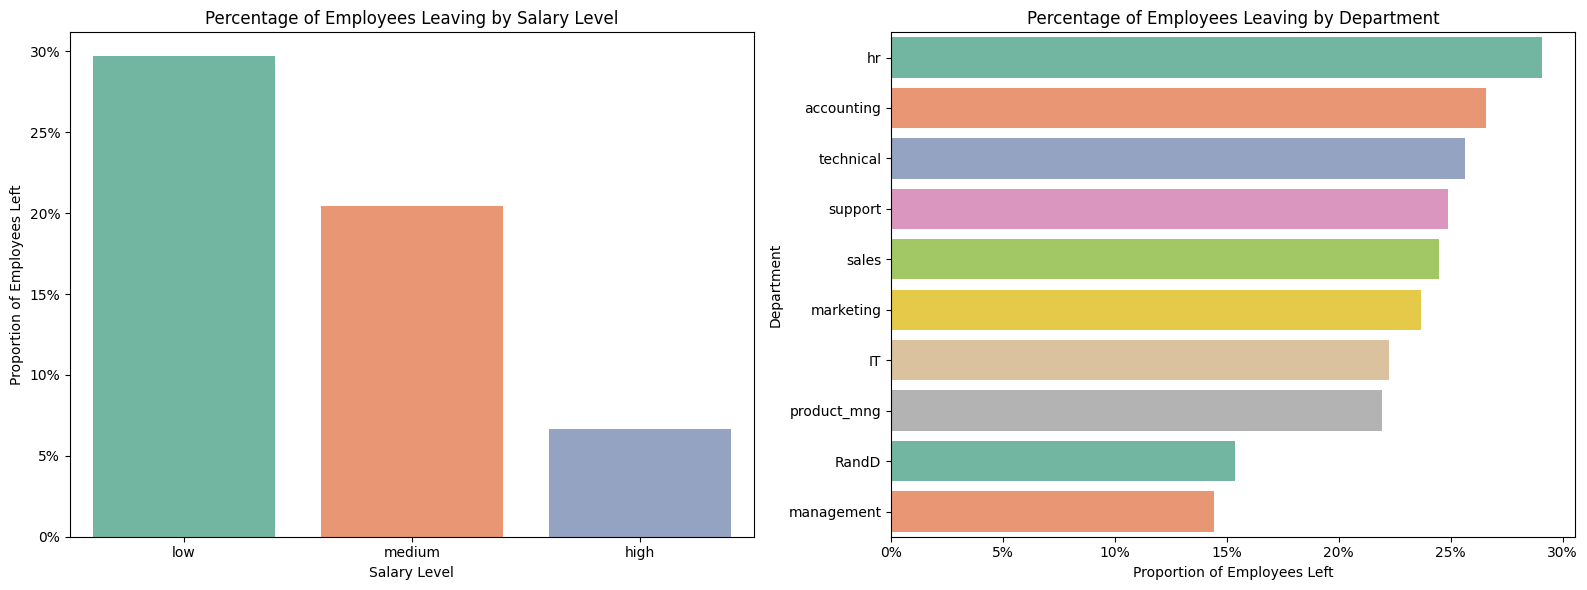

In [6]:
# 3. Visualizing Impact of Salary and Department on Retention using Bar Charts (Retention Rates)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Calculate retention rate by Salary
salary_rate = df.groupby('salary')['left'].mean().reset_index()
sns.barplot(data=salary_rate, x='salary', y='left', ax=axes[0], palette='Set2', order=['low', 'medium', 'high'])
axes[0].set_title('Percentage of Employees Leaving by Salary Level')
axes[0].set_xlabel('Salary Level')
axes[0].set_ylabel('Proportion of Employees Left')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))

# Calculate retention rate by Department
dept_rate = df.groupby('Department')['left'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=dept_rate, y='Department', x='left', ax=axes[1], palette='Set2')
axes[1].set_title('Percentage of Employees Leaving by Department')
axes[1].set_xlabel('Proportion of Employees Left')
axes[1].set_ylabel('Department')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: '{:.0%}'.format(x)))

plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Select the identified features
features = ['satisfaction_level', 'average_montly_hours', 'promotion_last_5years', 'salary']
X = df[features].copy()
y = df['left']


# 2. Convert categorical 'salary' variable into dummy indicator variables
X = pd.get_dummies(X, columns=['salary'], drop_first=True)
# 3. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

# 4. Initialize and fit the Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# 5. Make predictions and print model evaluation metrics
y_pred = model.predict(X_test)

print("Model Accuracy:", accuracy_score(y_test, y_pred))


Model Accuracy: 0.7728888888888888
